
# Optimizing Travel Costs for Dental Tourism

**Author:** Ivet Uzunova

**Course:** Math Concepts for Developers


## 1. Introduction

The idea for this project is inspired by my professional experience. My work has given me insight into the practical challenges of planning and optimizing travel costs for patients seeking dental treatment in Bulgaria. This inspired me to explore how mathematical concepts and Python programming can be applied to compare travel options and identify the lowest possible travel costs.

International patients from DACH (Germany, Austria and Switzerland) travel to Varna, Bulgaria for dental treatment (major dental procedures such as implants, crowns, "Hollywood smile").

Their travel expenses include flights (round-trip ticket), hotel accommodation, and airport transfers in Varna (airport pickup and drop-off transfer).


This project aims to apply mathematical and Python skills to compare travel options and identify the lowest-cost feasible combination.

## 2. Project Objectives

- Compare flight, hotel, and transfer options.
- Calculate total travel costs.
- Find the cheapest feasible travel plan.
- Analyze how the length of stay affects travel costs.
- Analyze how seasonal differences in hotel prices affect travel costs.
- Analyze how discount based on the booking date affects travel costs.
- General conclusion based on the experiments conducted.

## 3. Data and Assumptions

The project entirely uses illustrative data for the purposes of the experiments. The prices do not represent actual market prices.

Regarding flights, the analysis assumes that three different airlines are being compared based on the prices they offer for a specific flight.

Regarding transfers, it is assumed that the dental clinic works with two transportation companies, each of which sets its own prices for specific dates according to its own pricing policies. Since these policies are outside the scope of this analysis, they will not be examined in detail. The objective is simply to select the transfer option with the lowest available price.

This project examines in detail how the length of stay affects total travel costs, how seasonal differences in hotel prices influence total travel costs, and how the dental clinic's early booking discount policy affects total travel costs.

The clinic's discount policy is also illustrative and does not represent the actual policy of any specific real dental clinic. 

The analysis focuses on travel expenses and excludes the cost of dental treatment.


In [1]:

# Example travel prices in euros (EUR)

flights = {
    "Flight A": 180,
    "Flight B": 220,
    "Flight C": 200
}

hotel_prices_per_night = {
    "Hotel A": 60,
    "Hotel B": 80,
    "Hotel C": 50
}

transfer_prices = {
    "Transfer A": 40,
    "Transfer B": 60
}

# Required length of stay
nights = 3

print("Available flights:", flights)
print("Hotel prices per night:", hotel_prices_per_night)
print("Transfer prices:", transfer_prices)
print("Required nights:", nights)


Available flights: {'Flight A': 180, 'Flight B': 220, 'Flight C': 200}
Hotel prices per night: {'Hotel A': 60, 'Hotel B': 80, 'Hotel C': 50}
Transfer prices: {'Transfer A': 40, 'Transfer B': 60}
Required nights: 3


In [2]:

# Select one travel option

flight_price = flights["Flight A"]
hotel_price = hotel_prices_per_night["Hotel A"]
transfer_price = transfer_prices["Transfer A"]

# Calculate the total travel cost
total_cost = (
    flight_price
    + nights * hotel_price
    + transfer_price
)

print(f"Total travel cost: €{total_cost}")


Total travel cost: €400


In [3]:

def calculate_total_cost(flight_price, hotel_price, transfer_price, nights):
    total = flight_price + hotel_price * nights + transfer_price
    return total


# Test the function
example_cost = calculate_total_cost(180, 60, 40, 3)

print(f"Example total cost: €{example_cost}")


Example total cost: €400


In [4]:
assert calculate_total_cost(180, 60, 40, 3) == 400
assert calculate_total_cost(180, 50, 40, 3) == 370
assert calculate_total_cost(220, 80, 60, 3) == 520

print("All tests passed successfully!")

All tests passed successfully!


In [5]:

# Compare all possible travel combinations

best_option = None
lowest_cost = float("inf")

for flight_name, flight_price in flights.items():
    for hotel_name, hotel_price in hotel_prices_per_night.items():
        for transfer_name, transfer_price in transfer_prices.items():

            total = calculate_total_cost(
                flight_price,
                hotel_price,
                transfer_price,
                nights
            )

            if total < lowest_cost:
                lowest_cost = total
                best_option = (
                    flight_name,
                    hotel_name,
                    transfer_name
                )

print("Cheapest option:")
print("Flight:", best_option[0])
print("Hotel:", best_option[1])
print("Transfer:", best_option[2])
print(f"Total cost: €{lowest_cost}")


Cheapest option:
Flight: Flight A
Hotel: Hotel C
Transfer: Transfer A
Total cost: €370


Using Python, the cheapest flight, hotel, and transfer are identified. Combining these options results in the lowest overall travel cost.


## 4. Mathematical Model

The total travel cost is calculated using the following formula:

$$
C_{\text{total}} = C_{\text{flight}} + n \cdot C_{\text{hotel}} + C_{\text{transfer}}
$$

Where:

- $C_{\text{flight}}$ is the price of the flight.
- $n$ is the number of hotel nights.
- $C_{\text{hotel}}$ is the price per hotel night.
- $C_{\text{transfer}}$ is the transfer cost.

The objective is to minimize the total travel cost by selecting one flight, one hotel, and one transfer option.

Mathematically, this can be written as:

$$
C_{\min} = \min_{i,j,k}
\left(
F_i + nH_j + T_k
\right)
$$

where $F_i$, $H_j$, and $T_k$ represent the prices of the available flight, hotel, and transfer options.


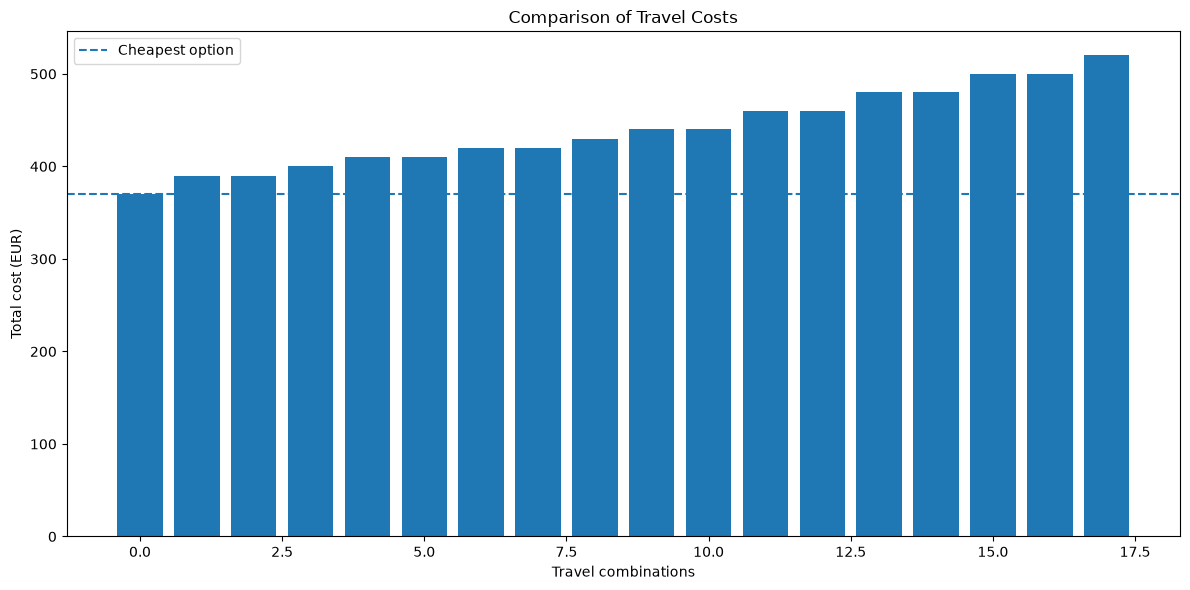

Number of combinations: 18
Cheapest cost: 370
Most expensive cost: 520


In [6]:

import matplotlib.pyplot as plt

# Store the total cost of each combination
all_costs = []

for flight_name, flight_price in flights.items():
    for hotel_name, hotel_price in hotel_prices_per_night.items():
        for transfer_name, transfer_price in transfer_prices.items():
            total = calculate_total_cost(
                flight_price,
                hotel_price,
                transfer_price,
                nights
            )

            label = f"{flight_name}, {hotel_name}, {transfer_name}"
            all_costs.append((label, total))

# Sort combinations from cheapest to most expensive
all_costs.sort(key=lambda item: item[1])

# Prepare data for the chart
labels = [item[0] for item in all_costs]
costs = [item[1] for item in all_costs]

plt.figure(figsize=(12, 6))
plt.bar(range(len(costs)), costs)
plt.axhline(lowest_cost, linestyle="--", label="Cheapest option")
plt.xlabel("Travel combinations")
plt.ylabel("Total cost (EUR)")
plt.title("Comparison of Travel Costs")
plt.legend()
plt.tight_layout()
plt.show()

print("Number of combinations:", len(all_costs))
print("Cheapest cost:", lowest_cost)
print("Most expensive cost:", max(costs))


In [7]:

# Calculate potential savings

most_expensive_cost = max(costs)
cheapest_cost = min(costs)

savings = most_expensive_cost - cheapest_cost
savings_percentage = (savings / most_expensive_cost) * 100

print(f"Cheapest option: €{cheapest_cost}")
print(f"Most expensive option: €{most_expensive_cost}")
print(f"Potential savings: €{savings}")
print(f"Potential savings percentage: {savings_percentage:.2f}%")


Cheapest option: €370
Most expensive option: €520
Potential savings: €150
Potential savings percentage: 28.85%


This shows that the difference between the cheapest and the most expensive combination is significant. Therefore, it is important to have a method for identifying the cheapest option so that patients can be offered the best possible price.

## 5. Optimization Method: Exhaustive Search
The optimization problem is solved using exhaustive search. The algorithm evaluates every possible combination of flight, hotel, and transfer options and calculates its total travel cost.

Since there are 3 flight options, 3 hotel options, and 2 transfer options, the total number of combinations is:

$$N = 3 \times 3 \times 2 = 18$$

The algorithm compares the total costs of all 18 combinations and selects the combination with the minimum cost. Because every possible combination is evaluated, the algorithm identifies the lowest-cost option among the combinations included in the project.

This method is suitable for the current problem because the number of options is small. However, the number of combinations grows multiplicatively as more options are added, which can make exhaustive search inefficient for larger problems.

The method also assumes that all listed combinations are feasible. In a real travel-planning scenario, availability, flight schedules, and other practical constraints would need to be considered.

## 6. Statistical Analysis of Travel Costs

To better understand the distribution of travel costs, we calculate the mean, median, and range of all 18 possible travel combinations.

These statistics help us compare the typical cost with the cheapest and most expensive options.

In [8]:
import statistics

mean_cost = statistics.mean(costs)
median_cost = statistics.median(costs)
cost_range = max(costs) - min(costs)

print(f"Mean travel cost: €{mean_cost:.2f}")
print(f"Median travel cost: €{median_cost:.2f}")
print(f"Minimum travel cost: €{min(costs)}")
print(f"Maximum travel cost: €{max(costs)}")
print(f"Range of travel costs: €{cost_range}")

Mean travel cost: €440.00
Median travel cost: €435.00
Minimum travel cost: €370
Maximum travel cost: €520
Range of travel costs: €150


### Interpretation of Statistical Results

The mean travel cost is €440, while the median is €435. These values indicate the central tendency of the 18 possible travel combinations.

The minimum cost is €370, and the maximum cost is €520, resulting in a range of €150. This shows that the choice of flight, hotel, and transfer can have a meaningful impact on total travel expenses.

The cheapest combination provides a lower-cost option under the assumptions of this model. However, the results are based on illustrative prices and do not account for availability, travel convenience, or changes in real market prices.

## 7. Experiment: Effect of Length of Stay

The length of stay affects the total travel cost because accommodation is charged per night. In this experiment, the minimum overall travel cost is calculated for stays of 1, 3, 5, and 7 nights.

For each stay duration, the algorithm evaluates all flight, hotel, and transfer combinations and identifies the lowest-cost option.  This makes it possible to examine how the length of stay influences the minimum travel cost.

In [9]:

stay_durations = [1, 3, 5, 7]
stay_results = []

for stay_nights in stay_durations:
    best_cost = float("inf")
    best_combination = None

    for flight_name, flight_price in flights.items():
        for hotel_name, hotel_price in hotel_prices_per_night.items():
            for transfer_name, transfer_price in transfer_prices.items():

                total_cost = calculate_total_cost(
                    flight_price,
                    hotel_price,
                    transfer_price,
                    stay_nights
                )

                if total_cost < best_cost:
                    best_cost = total_cost
                    best_combination = (
                        flight_name,
                        hotel_name,
                        transfer_name
                    )

    stay_results.append({
        "nights": stay_nights,
        "minimum_cost": best_cost,
        "combination": best_combination
    })

for result in stay_results:
    print(
        f'{result["nights"]} nights: '
        f'€{result["minimum_cost"]} - '
        f'{result["combination"]}'
    )


1 nights: €270 - ('Flight A', 'Hotel C', 'Transfer A')
3 nights: €370 - ('Flight A', 'Hotel C', 'Transfer A')
5 nights: €470 - ('Flight A', 'Hotel C', 'Transfer A')
7 nights: €570 - ('Flight A', 'Hotel C', 'Transfer A')


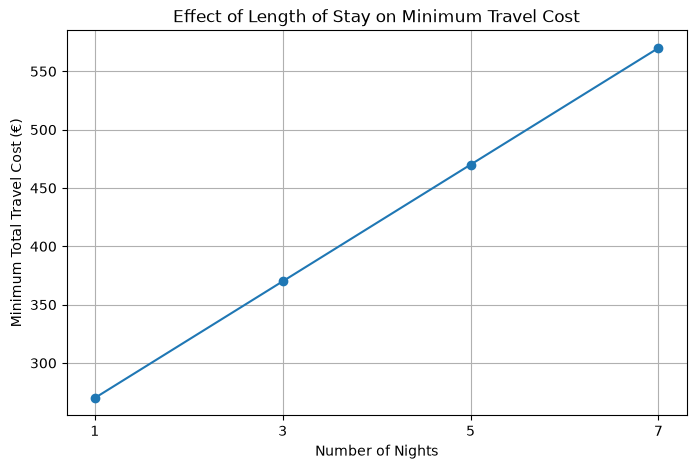

In [10]:

import matplotlib.pyplot as plt

stay_nights_values = [
    result["nights"] for result in stay_results
]

minimum_costs = [
    result["minimum_cost"] for result in stay_results
]

plt.figure(figsize=(8, 5))
plt.plot(stay_nights_values, minimum_costs, marker="o")
plt.title("Effect of Length of Stay on Minimum Travel Cost")
plt.xlabel("Number of Nights")
plt.ylabel("Minimum Total Travel Cost (€)")
plt.xticks(stay_nights_values)
plt.grid(True)
plt.show()


### Interpretation of Results

The experiment shows that the minimum travel cost increases as the length of stay increases. With the current illustrative prices, each additional hotel night adds €50 to the total cost because Hotel C is the cheapest accommodation option at €50 per night.

The same flight, hotel, and transfer combination remains the cheapest for all four stay durations. This happens because the flight and transfer prices remain fixed, while the hotel cost increases proportionally with the number of nights.

For this reason, it is advisable for the dental clinic to plan patients’ treatments so that they can be completed within the shortest possible stay. In this way, the clinic would be able to offer lower overall travel costs.

## 8. Experiment: Seasonal Variation in Hotel Prices

Hotel prices may vary depending on the season. To investigate how seasonality affects the total travel budget, this experiment assumes that hotel prices are 20% higher during the summer months of June, July, and August.

The model uses the original hotel prices from September to May and applies a 20% increase from June to August. Flight and transfer prices remain unchanged, and the length of stay is fixed at three nights.

This is an illustrative assumption for the analysis and does not represent verified pricing data from specific hotels.

The objective is to compare the total travel costs in summer and outside the summer season.

In [11]:
def calculate_seasonal_hotel_price(base_price, month):
    if month in [6, 7, 8]:
        return base_price * 1.20
    else:
        return base_price

In [12]:
base_price = 50

print("May:", calculate_seasonal_hotel_price(base_price, 5))
print("June:", calculate_seasonal_hotel_price(base_price, 6))
print("August:", calculate_seasonal_hotel_price(base_price, 8))
print("September:", calculate_seasonal_hotel_price(base_price, 9))

May: 50
June: 60.0
August: 60.0
September: 50


In [13]:
# Experiment: Seasonal Variation in Hotel Prices

# Define the length of stay
required_nights = 3

# Store the results for all travel combinations
seasonal_results = []

# Compare regular prices with summer prices
for flight_name, flight_price in flights.items():
    for hotel_name, hotel_price in hotel_prices_per_night.items():
        for transfer_name, transfer_price in transfer_prices.items():

            # Calculate the total cost outside the summer season
            regular_cost = calculate_total_cost(
                flight_price,
                hotel_price,
                transfer_price,
                required_nights
            )

            # Increase the hotel price by 20% for the summer season
            summer_hotel_price = calculate_seasonal_hotel_price(
                hotel_price, 7
            )

            # Calculate the total cost during the summer season
            summer_cost = calculate_total_cost(
                flight_price,
                summer_hotel_price,
                transfer_price,
                required_nights
            )

            # Save the results
            seasonal_results.append({
                "flight": flight_name,
                "hotel": hotel_name,
                "transfer": transfer_name,
                "regular_cost": regular_cost,
                "summer_cost": summer_cost,
                "difference": summer_cost - regular_cost
            })

# Display the results
print("Number of combinations:", len(seasonal_results))
print()

for result in seasonal_results:
    print(
        f'{result["flight"]} + {result["hotel"]} + '
        f'{result["transfer"]}: '
        f'Regular = €{result["regular_cost"]:.2f}, '
        f'Summer = €{result["summer_cost"]:.2f}, '
        f'Increase = €{result["difference"]:.2f}'
    )

Number of combinations: 18

Flight A + Hotel A + Transfer A: Regular = €400.00, Summer = €436.00, Increase = €36.00
Flight A + Hotel A + Transfer B: Regular = €420.00, Summer = €456.00, Increase = €36.00
Flight A + Hotel B + Transfer A: Regular = €460.00, Summer = €508.00, Increase = €48.00
Flight A + Hotel B + Transfer B: Regular = €480.00, Summer = €528.00, Increase = €48.00
Flight A + Hotel C + Transfer A: Regular = €370.00, Summer = €400.00, Increase = €30.00
Flight A + Hotel C + Transfer B: Regular = €390.00, Summer = €420.00, Increase = €30.00
Flight B + Hotel A + Transfer A: Regular = €440.00, Summer = €476.00, Increase = €36.00
Flight B + Hotel A + Transfer B: Regular = €460.00, Summer = €496.00, Increase = €36.00
Flight B + Hotel B + Transfer A: Regular = €500.00, Summer = €548.00, Increase = €48.00
Flight B + Hotel B + Transfer B: Regular = €520.00, Summer = €568.00, Increase = €48.00
Flight B + Hotel C + Transfer A: Regular = €410.00, Summer = €440.00, Increase = €30.00
Flig

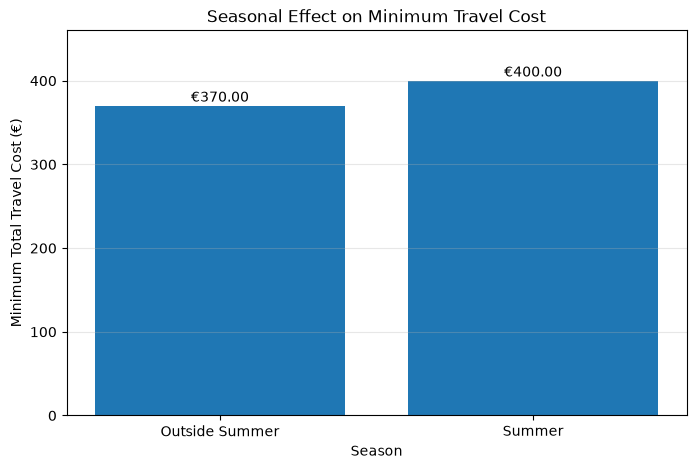

In [14]:
import matplotlib.pyplot as plt

# Find the minimum cost in each season
minimum_regular_cost = min(
    result["regular_cost"] for result in seasonal_results
)

minimum_summer_cost = min(
    result["summer_cost"] for result in seasonal_results
)

# Create the comparison chart
seasons = ["Outside Summer", "Summer"]
minimum_costs = [minimum_regular_cost, minimum_summer_cost]

plt.figure(figsize=(8, 5))
plt.bar(seasons, minimum_costs)

plt.title("Seasonal Effect on Minimum Travel Cost")
plt.xlabel("Season")
plt.ylabel("Minimum Total Travel Cost (€)")

for i, cost in enumerate(minimum_costs):
    plt.text(i, cost + 5, f"€{cost:.2f}", ha="center")

plt.ylim(0, max(minimum_costs) + 60)
plt.grid(axis="y", alpha=0.3)
plt.show()

### Interpretation of Results

The analysis shows that a 20% increase in hotel prices during the summer months raises the minimum total travel cost from €370 to €400 for a three-night stay. This represents an increase of €30, or approximately 8.1% of the original total cost. 

The cheapest combination remains Flight A, Hotel C, and Transfer A. The reason is that the same percentage increase is applied to every hotel's base price, while flight and transfer prices remain unchanged.

The results demonstrate that hotel prices for summer season affect the overall travel budget.
However, the summer season gives patients the opportunity to combine dental tourism with a seaside holiday, making this increase in travel costs less of a concern for those who enjoy spending time on the beach. 

## 9. Experiment: Early Booking Discounts

The dental clinic has a policy to encourage patients to book their treatment early. Early booking discounts may encourage patients to plan their dental tourism trips in advance. In this experiment, the discount depends on the number of months between booking and arrival.

The discount policy used in this model is:

- More than 6 months before arrival: 30% discount.
- From 3 to 6 months before arrival, inclusive: 15% discount.
- Less than 3 months before arrival: no discount.

The discount is applied to the entire travel cost, including flights, accommodation, and transfers. Dental treatment costs are excluded from the model.

The final travel cost is calculated as:

$$C_{final} = C_{total} \times (1-d)$$

where \(C_{total}\) is the original travel cost and \(d\) is the discount rate.

The discount percentages are illustrative assumptions created for this project and do not represent verified offers from a specific clinic.

In [15]:
def calculate_discounted_cost(total_cost, months_before_arrival):
    if months_before_arrival > 6:
        discount_rate = 0.30
    elif months_before_arrival >= 3:
        discount_rate = 0.15
    else:
        discount_rate = 0.0

    final_cost = total_cost * (1 - discount_rate)
    return final_cost

In [16]:
original_cost = 370

for months in [7, 4, 2]:
    final_cost = calculate_discounted_cost(
        original_cost,
        months
    )

    savings = original_cost - final_cost

    print(
        f"Booking {months} months before arrival: "
        f"Final cost = €{final_cost:.2f}, "
        f"Savings = €{savings:.2f}"
    )

Booking 7 months before arrival: Final cost = €259.00, Savings = €111.00
Booking 4 months before arrival: Final cost = €314.50, Savings = €55.50
Booking 2 months before arrival: Final cost = €370.00, Savings = €0.00


In [17]:
assert calculate_discounted_cost(370, 2) == 370
assert calculate_discounted_cost(370, 3) == 314.5
assert calculate_discounted_cost(370, 6) == 314.5
assert calculate_discounted_cost(370, 7) == 259

print("All tests passed successfully!")

All tests passed successfully!


In [18]:

# Define the booking periods
booking_months = [7, 4, 2]

# Store discounted costs for all travel combinations
discount_results = []

for months in booking_months:
    for flight_name, flight_price in flights.items():
        for hotel_name, hotel_price in hotel_prices_per_night.items():
            for transfer_name, transfer_price in transfer_prices.items():

                total_cost = calculate_total_cost(
                    flight_price,
                    hotel_price,
                    transfer_price,
                    required_nights
                )

                discounted_cost = calculate_discounted_cost(
                    total_cost,
                    months
                )

                discount_results.append({
                    "months_before_arrival": months,
                    "flight": flight_name,
                    "hotel": hotel_name,
                    "transfer": transfer_name,
                    "discounted_cost": discounted_cost
                })

print("Number of discount scenarios:", len(discount_results))


Number of discount scenarios: 54


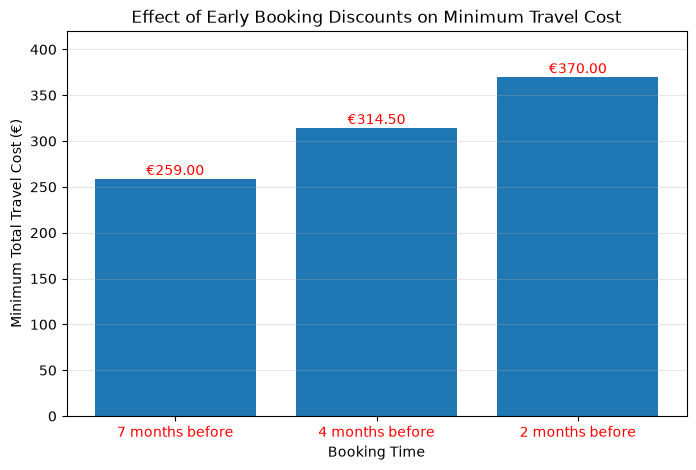

In [19]:
import matplotlib.pyplot as plt

# Find the minimum cost for each booking period
minimum_costs = []

for months in booking_months:
    period_results = [
        result for result in discount_results
        if result["months_before_arrival"] == months
    ]

    best_cost = min(
        result["discounted_cost"]
        for result in period_results
    )

    minimum_costs.append(best_cost)

# Create the chart
booking_labels = [
    "7 months before",
    "4 months before",
    "2 months before"
]

plt.figure(figsize=(8, 5))
plt.bar(booking_labels, minimum_costs)

plt.title("Effect of Early Booking Discounts on Minimum Travel Cost")
plt.xlabel("Booking Time")
plt.ylabel("Minimum Total Travel Cost (€)")

plt.xticks(color="red")


for i, cost in enumerate(minimum_costs):
    plt.text(
        i,
        cost + 4,
        f"€{cost:.2f}",
        ha="center",
        color="red"
    )

plt.ylim(0, max(minimum_costs) + 50)
plt.grid(axis="y", alpha=0.3)
plt.show()

### Interpretation of Results

The analysis evaluates three booking periods. For this experiment, the length of stay is fixed at three nights, using the same base travel-cost scenario as in the previous analysis.

Under the assumed discount policy, booking more than six months in advance reduces the minimum travel cost from €370 to €259, saving €111. Booking four months in advance reduces the cost to €314.50, saving €55.50. Booking two months in advance provides no discount.

The cheapest combination remains Flight A, Hotel C, and Transfer A in all three scenarios. This is because the same discount rate is applied to every travel combination within each booking period, so the relative ranking of the options does not change.

These results show that, under the model's assumptions, early booking can substantially reduce travel expenses.

## 10. Final Conclusion and Recommendations

This project analyzes how flight prices, hotel accommodation, transfer costs, length of stay, seasonal price changes, and early booking discounts affect the total travel expenses of patients traveling to Bulgaria for dental treatment.

The results show that each of the analyzed strategies can reduce travel costs under the assumptions of the model.

First, **booking more than six months in advance** provides the greatest savings under the assumed discount policy. A 30% discount reduces the minimum modeled travel cost from €370 to €259, saving €111.

Second, **planning the trip outside the summer season** helps reduce accommodation expenses. In the model, hotel prices are 20% higher in June, July, and August. For the cheapest travel combination and a three-night stay, the total cost increases from €370 to €400 during the summer months.

Third, **minimizing the length of stay** reduces the overall travel budget. Under the modeled prices, the cheapest combination costs €270 for one night, €370 for three nights, €470 for five nights, and €570 for seven nights. Each additional night increases the cost by €50 for this combination. 

Based on the separate findings of these experiments, patients may reduce their travel expenses by booking early, choosing dates outside the summer season, and keeping their stay as short as the treatment plan reasonably allows.

However, the shortest stay must remain compatible with the patient's clinical needs and the dentist's treatment schedule. The model should support travel planning, not determine the medically appropriate duration of treatment.

Finally, the analysis is based on illustrative prices and assumptions rather than verified live market data. Actual costs and available discounts may vary depending on travel dates, providers, and individual treatment plans. 

Overall, the project demonstrates how mathematical and Python skills can help compare travel options, estimate potential savings, and support more informed budget planning for dental tourism.    